# Uber NCR Ride Analysis

## 1. Load the Dataset

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = r"D:\Uber Ride Analysis\ncr_ride_bookings.csv"
df = pd.read_csv(file_path)

## 2. Explore the Dataset

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (150000, 21)


In [2]:
print(df.columns.tolist())

['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']


In [3]:
print(df.head())

         Date      Time    Booking ID   Booking Status   Customer ID  \
0  2024-03-23  12:29:38  "CNR5884300"  No Driver Found  "CID1982111"   
1  2024-11-29  18:01:39  "CNR1326809"       Incomplete  "CID4604802"   
2  2024-08-23  08:56:10  "CNR8494506"        Completed  "CID9202816"   
3  2024-10-21  17:17:25  "CNR8906825"        Completed  "CID2610914"   
4  2024-09-16  22:08:00  "CNR1950162"        Completed  "CID9933542"   

    Vehicle Type      Pickup Location      Drop Location  Avg VTAT  Avg CTAT  \
0          eBike          Palam Vihar            Jhilmil       NaN       NaN   
1       Go Sedan        Shastri Nagar  Gurgaon Sector 56       4.9      14.0   
2           Auto              Khandsa      Malviya Nagar      13.4      25.8   
3  Premier Sedan  Central Secretariat           Inderlok      13.1      28.5   
4           Bike     Ghitorni Village        Khan Market       5.3      19.6   

   ...  Reason for cancelling by Customer Cancelled Rides by Driver  \
0  ...         

In [8]:
print(df.dtypes)

Date                                     str
Time                                     str
Booking ID                               str
Booking Status                           str
Customer ID                              str
Vehicle Type                             str
Pickup Location                          str
Drop Location                            str
Avg VTAT                             float64
Avg CTAT                             float64
Cancelled Rides by Customer          float64
Reason for cancelling by Customer        str
Cancelled Rides by Driver            float64
Driver Cancellation Reason               str
Incomplete Rides                     float64
Incomplete Rides Reason                  str
Booking Value                        float64
Ride Distance                        float64
Driver Ratings                       float64
Customer Rating                      float64
Payment Method                           str
dtype: object


In [4]:
print(df.isnull().sum())

Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer Rating                       57000
Payment Method                        48000
dtype: int64


## 3. Initial Data Quality Checks

In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer Rating                       57000
Payment Method                        48000
dtype: int64


In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
print("Booking Status Counts:")
print(df["Booking Status"].value_counts())

Booking Status Counts:
Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64


In [7]:
status_percentage = (
    df["Booking Status"].value_counts(normalize=True) * 100
).round(2)

print(status_percentage)

Booking Status
Completed                62.0
Cancelled by Driver      18.0
No Driver Found           7.0
Cancelled by Customer     7.0
Incomplete                6.0
Name: proportion, dtype: float64


## 4. Validate Date and Time

In [9]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print(df["Date"].dtype)


datetime64[us]


In [10]:
df["Time"] = pd.to_datetime(df["Time"], format="%H:%M:%S", errors="coerce").dt.time

print(df["Time"].dtype)


object


In [11]:
print("Invalid dates:", df["Date"].isna().sum())
print("Invalid times:", df["Time"].isna().sum())


Invalid dates: 0
Invalid times: 0


## 5. Clean and Validate Booking IDs

In [8]:
df["Booking ID"] = df["Booking ID"].str.strip('"')

print("Sample Booking IDs:")
print(df["Booking ID"].head())

Sample Booking IDs:
0    CNR5884300
1    CNR1326809
2    CNR8494506
3    CNR8906825
4    CNR1950162
Name: Booking ID, dtype: str


In [9]:
df["Customer ID"] = df["Customer ID"].str.strip('"')

print("Sample Customer IDs:")
print(df["Customer ID"].head())

Sample Customer IDs:
0    CID1982111
1    CID4604802
2    CID9202816
3    CID2610914
4    CID9933542
Name: Customer ID, dtype: str


In [10]:
print("Repeated Booking ID rows:", df["Booking ID"].duplicated().sum())
print("Unique Booking IDs:", df["Booking ID"].nunique())
print("Total rows:", len(df))

Repeated Booking ID rows: 1233
Unique Booking IDs: 148767
Total rows: 150000


In [11]:
print(
    df["Booking ID"]
    .value_counts()
    .value_counts()
    .sort_index()
)

count
1    147543
2      1215
3         9
Name: count, dtype: int64


In [12]:
duplicate_ids = df[df["Booking ID"].duplicated(keep=False)]

print(
    duplicate_ids[
        ["Booking ID", "Booking Status", "Date", "Time"]
    ].head(10)
)

     Booking ID       Booking Status        Date      Time
146  CNR2687237            Completed  2024-04-15  19:03:28
248  CNR5380412            Completed  2024-02-01  09:13:13
317  CNR5071968            Completed  2024-10-10  03:56:19
397  CNR2290384            Completed  2024-04-28  01:17:51
493  CNR3466923            Completed  2024-02-11  17:05:28
557  CNR5743864  Cancelled by Driver  2024-04-09  17:41:41
596  CNR6919794            Completed  2024-10-21  11:46:44
686  CNR7417664      No Driver Found  2024-03-14  10:45:22
764  CNR1197334            Completed  2024-03-30  13:24:41
864  CNR3011900      No Driver Found  2024-05-11  19:53:38


## 6. Validate Numeric Values

In [13]:
print("Negative Booking Values:", (df["Booking Value"] < 0).sum())

Negative Booking Values: 0


In [14]:
print("Negative Ride Distances:", (df["Ride Distance"] < 0).sum())

Negative Ride Distances: 0


In [15]:
invalid_driver_ratings = (
    (df["Driver Ratings"] < 0) |
    (df["Driver Ratings"] > 5)
)

print("Invalid Driver Ratings:", invalid_driver_ratings.sum())

Invalid Driver Ratings: 0


In [16]:
invalid_customer_ratings = (
    (df["Customer Rating"] < 0) |
    (df["Customer Rating"] > 5)
)

print("Invalid Customer Ratings:", invalid_customer_ratings.sum())

Invalid Customer Ratings: 0


## 7. Investigate Missing Values by Booking Status

In [17]:
check_columns = [
    "Booking Value",
    "Ride Distance",
    "Driver Ratings",
    "Customer Rating",
    "Avg VTAT",
    "Avg CTAT",
    "Payment Method"
]

for status in df["Booking Status"].dropna().unique():
    status_df = df[df["Booking Status"] == status]

    print("\nBooking Status:", status)
    print(status_df[check_columns].isna().sum())


Booking Status: No Driver Found
Booking Value      10500
Ride Distance      10500
Driver Ratings     10500
Customer Rating    10500
Avg VTAT           10500
Avg CTAT           10500
Payment Method     10500
dtype: int64

Booking Status: Incomplete
Booking Value         0
Ride Distance         0
Driver Ratings     9000
Customer Rating    9000
Avg VTAT              0
Avg CTAT              0
Payment Method        0
dtype: int64

Booking Status: Completed
Booking Value      0
Ride Distance      0
Driver Ratings     0
Customer Rating    0
Avg VTAT           0
Avg CTAT           0
Payment Method     0
dtype: int64

Booking Status: Cancelled by Driver
Booking Value      27000
Ride Distance      27000
Driver Ratings     27000
Customer Rating    27000
Avg VTAT               0
Avg CTAT           27000
Payment Method     27000
dtype: int64

Booking Status: Cancelled by Customer
Booking Value      10500
Ride Distance      10500
Driver Ratings     10500
Customer Rating    10500
Avg VTAT           

## 8. Validate Cancellation Reasons

In [18]:
customer_cancelled = df[
    df["Booking Status"] == "Cancelled by Customer"
]

print("Customer cancellations:", len(customer_cancelled))
print(
    "Missing customer cancellation reasons:",
    customer_cancelled["Reason for cancelling by Customer"].isna().sum()
)

Customer cancellations: 10500
Missing customer cancellation reasons: 0


In [19]:
driver_cancelled = df[
    df["Booking Status"] == "Cancelled by Driver"
]

print("Driver cancellations:", len(driver_cancelled))
print(
    "Missing driver cancellation reasons:",
    driver_cancelled["Driver Cancellation Reason"].isna().sum()
)

Driver cancellations: 27000
Missing driver cancellation reasons: 0


In [20]:
incomplete = df[df["Booking Status"] == "Incomplete"]

print("Incomplete bookings:", len(incomplete))
print(
    "Missing incomplete booking reasons:",
    incomplete["Incomplete Rides Reason"].isna().sum()
)

Incomplete bookings: 9000
Missing incomplete booking reasons: 0


## 9. Validate Missing Ride Details

In [22]:
no_driver = df[df["Booking Status"] == "No Driver Found"]

print("No-driver bookings:", len(no_driver))
print("Missing Avg VTAT:", no_driver["Avg VTAT"].isna().sum())

No-driver bookings: 10500
Missing Avg VTAT: 10500


In [23]:
completed = df[df["Booking Status"] == "Completed"]

print("Completed bookings:", len(completed))
print("Missing booking values:", completed["Booking Value"].isna().sum())
print("Missing ride distances:", completed["Ride Distance"].isna().sum())
print("Missing driver ratings:", completed["Driver Ratings"].isna().sum())
print("Missing customer ratings:", completed["Customer Rating"].isna().sum())
print("Missing Avg VTAT:", completed["Avg VTAT"].isna().sum())
print("Missing Avg CTAT:", completed["Avg CTAT"].isna().sum())
print("Missing payment methods:", completed["Payment Method"].isna().sum())

Completed bookings: 93000
Missing booking values: 0
Missing ride distances: 0
Missing driver ratings: 0
Missing customer ratings: 0
Missing Avg VTAT: 0
Missing Avg CTAT: 0
Missing payment methods: 0


## 10. Create Unique Ride ID and Hour Columns

In [83]:
df.insert(0, "ride_id", range(1, len(df) + 1))

print("Total Rows:", len(df))
print("Unique Ride IDs:", df["ride_id"].nunique())

Total Rows: 150000
Unique Ride IDs: 150000


In [33]:
df["Hour"] = pd.to_datetime(
    df["Time"].astype(str), format="%H:%M:%S"
).dt.hour.astype("Int64")

print(df[["Time", "Hour"]].head())

       Time  Hour
0  12:29:38    12
1  18:01:39    18
2  08:56:10     8
3  17:17:25    17
4  22:08:00    22


## 11. Save and Verify the Cleaned Dataset

In [36]:
df.to_csv(
    r"D:\Uber Ride Analysis\uber_ride_cleaned.csv",
    index=False,
    date_format="%Y-%m-%d"
)


print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [37]:
check_df = pd.read_csv(r"D:\Uber Ride Analysis\uber_ride_cleaned.csv")

print("Saved dataset shape:", check_df.shape)
print("Unique ride IDs:", check_df["ride_id"].nunique())
print("Columns:", check_df.columns.tolist())
print(check_df.head())

Saved dataset shape: (150000, 23)
Unique ride IDs: 150000
Columns: ['ride_id', 'Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method', 'Hour']
   ride_id        Date      Time  Booking ID   Booking Status Customer ID  \
0        1  2024-03-23  12:29:38  CNR5884300  No Driver Found  CID1982111   
1        2  2024-11-29  18:01:39  CNR1326809       Incomplete  CID4604802   
2        3  2024-08-23  08:56:10  CNR8494506        Completed  CID9202816   
3        4  2024-10-21  17:17:25  CNR8906825        Completed  CID2610914   
4        5  2024-09-16  22:08:00  CNR1950162        Completed  CID9933542   

    Vehicle Type      Pickup Location      Drop 

## 12. Analyse Monthly and Hourly Booking Trends

In [43]:
monthly_bookings = df["Date"].dt.month.value_counts().sort_index()
print("Monthly Booking Counts:")
print(monthly_bookings)

Monthly Booking Counts:
Date
1     12861
2     11927
3     12719
4     12199
5     12778
6     12440
7     12897
8     12636
9     12248
10    12651
11    12394
12    12250
Name: count, dtype: int64


In [44]:
hourly_bookings = df.groupby("Hour").size().sort_index()

print("Hourly Booking Counts:")
print(hourly_bookings)

Hourly Booking Counts:
Hour
0      1373
1      1360
2      1339
3      1383
4      1321
5      2786
6      4160
7      5450
8      6861
9      8234
10     9577
11     8390
12     7006
13     5470
14     7031
15     8202
16     9633
17    11044
18    12397
19    11047
20     9630
21     8103
22     5441
23     2762
dtype: int64


## 13. Visualise Booking Status Distribution

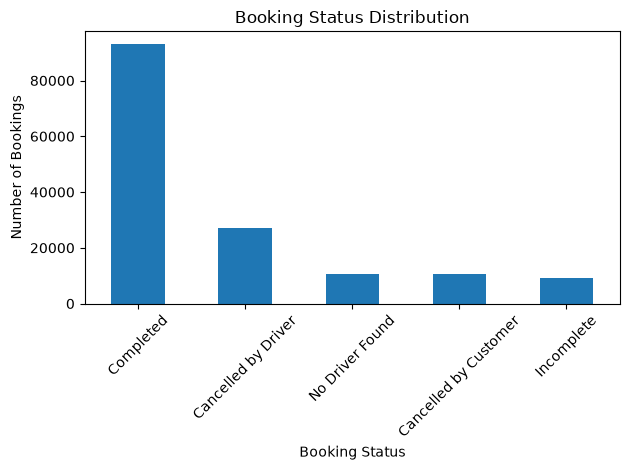

In [56]:
status_counts = df["Booking Status"].value_counts()

status_counts.plot(kind="bar")

plt.title("Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 14. Visualise Hourly Booking Trends

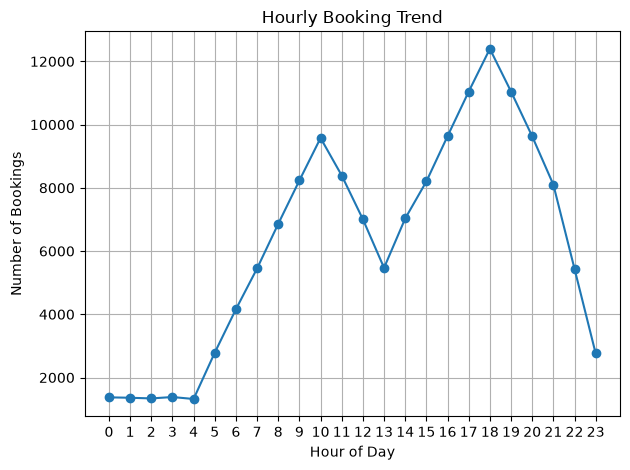

In [145]:
hourly_bookings = check_df["Hour"].value_counts().sort_index()

hourly_bookings.plot(kind="line", marker="o")

plt.title("Hourly Booking Trend")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Bookings")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

## 15. Analyse Cancellation Rates by Vehicle Type

In [47]:
vehicle_status = pd.crosstab(df["Vehicle Type"], df["Booking Status"])

print(vehicle_status)

Booking Status  Cancelled by Customer  Cancelled by Driver  Completed  \
Vehicle Type                                                            
Auto                             2680                 6643      23155   
Bike                             1575                 4077      14034   
Go Mini                          2097                 5330      18549   
Go Sedan                         1832                 5031      16676   
Premier Sedan                    1266                 3250      11252   
Uber XL                           327                  762       2783   
eBike                             723                 1907       6551   

Booking Status  Incomplete  No Driver Found  
Vehicle Type                                 
Auto                  2260             2681  
Bike                  1328             1503  
Go Mini               1815             2015  
Go Sedan              1642             1960  
Premier Sedan         1063             1280  
Uber XL             

In [48]:
vehicle_status["Total Bookings"] = vehicle_status.sum(axis=1)

vehicle_status["Total Cancelled"] = (
    vehicle_status["Cancelled by Driver"]
    + vehicle_status["Cancelled by Customer"]
)

vehicle_status["Cancellation Rate (%)"] = (
    vehicle_status["Total Cancelled"]
    / vehicle_status["Total Bookings"]
    * 100
)

print(vehicle_status.round(2))

Booking Status  Cancelled by Customer  Cancelled by Driver  Completed  \
Vehicle Type                                                            
Auto                             2680                 6643      23155   
Bike                             1575                 4077      14034   
Go Mini                          2097                 5330      18549   
Go Sedan                         1832                 5031      16676   
Premier Sedan                    1266                 3250      11252   
Uber XL                           327                  762       2783   
eBike                             723                 1907       6551   

Booking Status  Incomplete  No Driver Found  Total Bookings  Total Cancelled  \
Vehicle Type                                                                   
Auto                  2260             2681           37419             9323   
Bike                  1328             1503           22517             5652   
Go Mini               

## 16. Analyse Cancellation Reasons

In [49]:
print("Driver Cancellation Reasons:")
print(df["Driver Cancellation Reason"].value_counts())

Driver Cancellation Reasons:
Driver Cancellation Reason
Customer related issue                 6837
The customer was coughing/sick         6751
Personal & Car related issues          6726
More than permitted people in there    6686
Name: count, dtype: int64


In [50]:
print("Customer Cancellation Reasons:")
print(df["Reason for cancelling by Customer"].value_counts())

Customer Cancellation Reasons:
Reason for cancelling by Customer
Wrong Address                                   2362
Change of plans                                 2353
Driver is not moving towards pickup location    2335
Driver asked to cancel                          2295
AC is not working                               1155
Name: count, dtype: int64


In [51]:
print("Incomplete Booking Reasons:")
print(df["Incomplete Rides Reason"].value_counts())

Incomplete Booking Reasons:
Incomplete Rides Reason
Customer Demand      3040
Vehicle Breakdown    3012
Other Issue          2948
Name: count, dtype: int64


## 17. Analyse Driver Cancellations by Hour

In [52]:
driver_cancelled = df[
    df["Booking Status"] == "Cancelled by Driver"
]

cancel_by_hour = driver_cancelled.groupby("Hour").size().sort_index()

print(cancel_by_hour)

Hour
0      248
1      250
2      222
3      263
4      240
5      532
6      699
7     1006
8     1221
9     1492
10    1715
11    1461
12    1254
13    1001
14    1311
15    1472
16    1728
17    2003
18    2257
19    1998
20    1735
21    1395
22    1011
23     486
dtype: int64


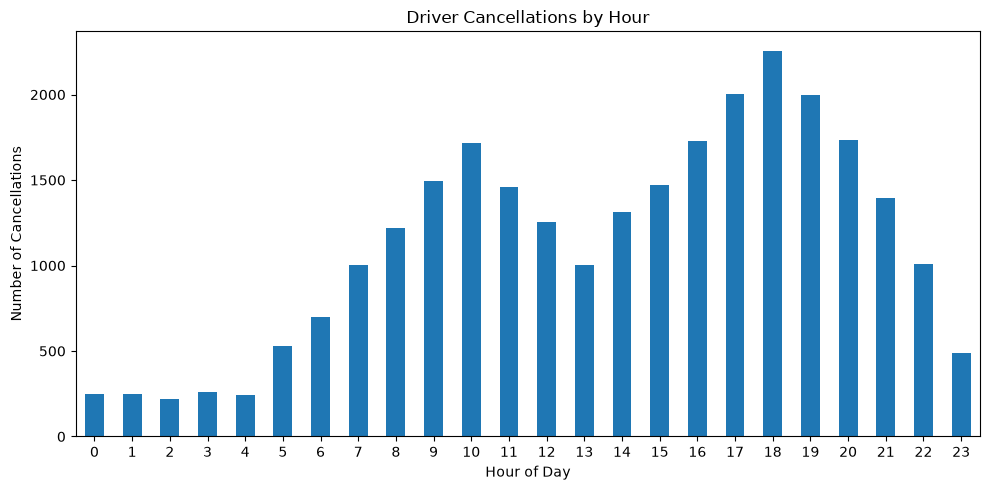

In [57]:
cancel_by_hour.plot(kind="bar", figsize=(10, 5))

plt.title("Driver Cancellations by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Cancellations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 18. Calculate Driver Cancellation Rates by Hour

In [61]:
hourly_status = pd.crosstab(df["Hour"], df["Booking Status"])

hourly_status["Total Bookings"] = hourly_status.sum(axis=1)

hourly_status["Driver Cancellation Rate (%)"] = (
    hourly_status["Cancelled by Driver"]
    / hourly_status["Total Bookings"]
    * 100
)

print(hourly_status["Driver Cancellation Rate (%)"].round(2))

Hour
0     18.06
1     18.38
2     16.58
3     19.02
4     18.17
5     19.10
6     16.80
7     18.46
8     17.80
9     18.12
10    17.91
11    17.41
12    17.90
13    18.30
14    18.65
15    17.95
16    17.94
17    18.14
18    18.21
19    18.09
20    18.02
21    17.22
22    18.58
23    17.60
Name: Driver Cancellation Rate (%), dtype: float64


## 19. Analyse Completed Ride Values

In [62]:
completed = df[df["Booking Status"] == "Completed"]

print("Average Ride Distance:", completed["Ride Distance"].mean().round(2))
print("Minimum Distance:", completed["Ride Distance"].min())
print("Maximum Distance:", completed["Ride Distance"].max())

Average Ride Distance: 26.0
Minimum Distance: 2.0
Maximum Distance: 50.0


In [63]:
print("Total Booking Value:", completed["Booking Value"].sum())
print("Average Booking Value:", completed["Booking Value"].mean().round(2))

Total Booking Value: 47260574.0
Average Booking Value: 508.18


## 20. Compare Booking Values by Vehicle Type

In [64]:
vehicle_value = (
    completed.groupby("Vehicle Type")["Booking Value"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Booking Value by Vehicle:")
print(vehicle_value)

Total Booking Value by Vehicle:
Vehicle Type
Auto             11727615.0
Go Mini           9411418.0
Go Sedan          8538560.0
Bike              7144913.0
Premier Sedan     5733655.0
eBike             3298157.0
Uber XL           1406256.0
Name: Booking Value, dtype: float64


In [65]:
average_vehicle_value = (
    completed.groupby("Vehicle Type")["Booking Value"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print("Average Booking Value by Vehicle:")
print(average_vehicle_value)

Average Booking Value by Vehicle:
Vehicle Type
Go Sedan         512.03
Premier Sedan    509.57
Bike             509.11
Go Mini          507.38
Auto             506.48
Uber XL          505.30
eBike            503.46
Name: Booking Value, dtype: float64


## 21. Visualise Booking Value by Vehicle Type

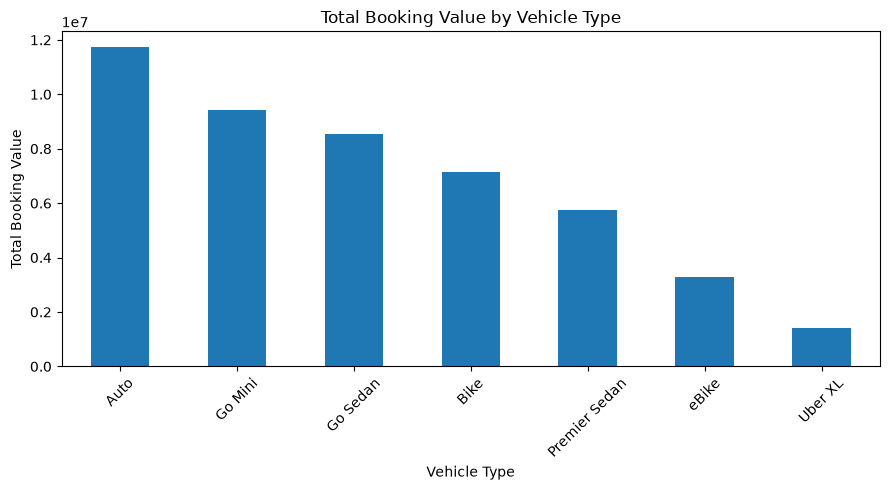

In [66]:
vehicle_value.plot(kind="bar", figsize=(9, 5))

plt.title("Total Booking Value by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Total Booking Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 22. Analyse Payment Methods

In [67]:
print("Payment Methods for Completed Rides:")
print(completed["Payment Method"].value_counts())

Payment Methods for Completed Rides:
Payment Method
UPI            41834
Cash           23114
Uber Wallet    11206
Credit Card     9320
Debit Card      7526
Name: count, dtype: int64


## 23. Compare Driver and Customer Ratings by Vehicle

In [68]:
driver_rating = (
    completed.groupby("Vehicle Type")["Driver Ratings"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Driver Ratings:")
print(driver_rating.round(2))

Average Driver Ratings:
Vehicle Type
Uber XL          4.24
Premier Sedan    4.23
Auto             4.23
Go Sedan         4.23
Bike             4.23
Go Mini          4.23
eBike            4.23
Name: Driver Ratings, dtype: float64


In [69]:
customer_rating = (
    completed.groupby("Vehicle Type")["Customer Rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Customer Ratings:")
print(customer_rating.round(2))

Average Customer Ratings:
Vehicle Type
Go Sedan         4.41
Uber XL          4.40
Go Mini          4.40
eBike            4.40
Bike             4.40
Premier Sedan    4.40
Auto             4.40
Name: Customer Rating, dtype: float64


## 24. Visualise Customer Ratings by Vehicle Type

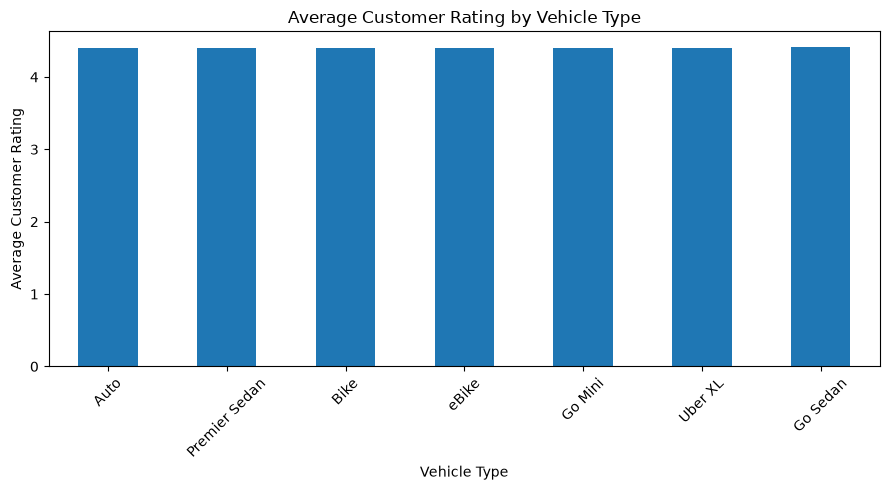

In [70]:
customer_rating.sort_values().plot(kind="bar", figsize=(9, 5))

plt.title("Average Customer Rating by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Customer Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 25. Compare Waiting-Time Measures by Vehicle Type

In [71]:
vtat = (
    completed.groupby("Vehicle Type")["Avg VTAT"]
    .mean()
    .sort_values(ascending=False)
)

print("Average VTAT by Vehicle:")
print(vtat.round(2))

Average VTAT by Vehicle:
Vehicle Type
Uber XL          8.59
Bike             8.57
eBike            8.54
Go Mini          8.52
Auto             8.49
Go Sedan         8.49
Premier Sedan    8.47
Name: Avg VTAT, dtype: float64


In [72]:
ctat = (
    completed.groupby("Vehicle Type")["Avg CTAT"]
    .mean()
    .sort_values(ascending=False)
)

print("Average CTAT by Vehicle:")
print(ctat.round(2))

Average CTAT by Vehicle:
Vehicle Type
Premier Sedan    30.09
Bike             30.07
Uber XL          30.07
eBike            30.05
Go Mini          30.05
Auto             30.03
Go Sedan         29.95
Name: Avg CTAT, dtype: float64


## 26. Compare Waiting-Time Measures by Hour

In [73]:
vtat_hour = completed.groupby("Hour")["Avg VTAT"].mean().sort_index()

print("Average VTAT by Hour:")
print(vtat_hour.round(2))

Average VTAT by Hour:
Hour
0     8.38
1     8.31
2     8.59
3     8.47
4     8.56
5     8.43
6     8.52
7     8.53
8     8.58
9     8.53
10    8.53
11    8.53
12    8.51
13    8.55
14    8.51
15    8.58
16    8.55
17    8.55
18    8.44
19    8.49
20    8.52
21    8.41
22    8.53
23    8.43
Name: Avg VTAT, dtype: float64


In [74]:
ctat_hour = completed.groupby("Hour")["Avg CTAT"].mean().sort_index()

print("Average CTAT by Hour:")
print(ctat_hour.round(2))

Average CTAT by Hour:
Hour
0     30.06
1     29.85
2     29.78
3     30.46
4     29.70
5     29.54
6     30.09
7     30.02
8     30.21
9     29.95
10    30.23
11    29.87
12    30.21
13    30.08
14    30.03
15    29.94
16    29.96
17    30.01
18    30.20
19    30.03
20    30.03
21    29.95
22    30.13
23    29.76
Name: Avg CTAT, dtype: float64


## 27. Analyse Pickup and Drop Locations

In [75]:
print("Top 10 Pickup Locations:")
print(df["Pickup Location"].value_counts().head(10))

Top 10 Pickup Locations:
Pickup Location
Khandsa             949
Barakhamba Road     946
Saket               931
Badarpur            921
Pragati Maidan      920
Madipur             919
AIIMS               918
Mehrauli            915
Dwarka Sector 21    914
Pataudi Chowk       907
Name: count, dtype: int64


In [76]:
print("Top 10 Drop Locations:")
print(df["Drop Location"].value_counts().head(10))

Top 10 Drop Locations:
Drop Location
Ashram                936
Basai Dhankot         917
Lok Kalyan Marg       916
Narsinghpur           913
Cyber Hub             912
Kalkaji               912
Kashmere Gate ISBT    909
Udyog Vihar           906
Lajpat Nagar          904
Madipur               902
Name: count, dtype: int64


In [77]:
print("Unique Pickup Locations:", df["Pickup Location"].nunique())
print("Unique Drop Locations:", df["Drop Location"].nunique())

Unique Pickup Locations: 176
Unique Drop Locations: 176


## 28. Analyse Customer Activity

In [78]:
print("Unique Customers:", df["Customer ID"].nunique())

Unique Customers: 148788


In [79]:
customer_rides = completed["Customer ID"].value_counts()

print(
    "Customers with Multiple Completed Rides:",
    (customer_rides > 1).sum()
)

Customers with Multiple Completed Rides: 450


## 29. Final Data Validation

In [84]:
print("Total Rows:", len(df))
print("Unique Ride IDs:", df["ride_id"].nunique())
print("Duplicate Ride IDs:", df["ride_id"].duplicated().sum())
print(
    "Duplicate Original Records:",
    df.drop(columns=["ride_id"]).duplicated().sum()
)
print("Missing Values:")
print(df.isnull().sum())

Total Rows: 150000
Unique Ride IDs: 150000
Duplicate Ride IDs: 0
Duplicate Original Records: 0
Missing Values:
ride_id                                   0
Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer 

## 30. Key Findings

- The dataset contains 150,000 ride-booking records.
- Approximately 62% of bookings are completed.
- Driver cancellations account for 18% of all bookings.
- Customer cancellations account for 7% of all bookings.
- No-driver-found and incomplete bookings account for another 13%.
- Booking activity is highest around 6 PM and lowest around 4 AM.
- Cancellation rates are broadly similar across vehicle types.
- Auto has the highest total booking value among completed rides.
- UPI is the most frequently used payment method for completed rides.
- Customer ratings and waiting-time measures show only small differences across vehicle types.

These findings describe the observed dataset and should not be interpreted as proof of cause and effect.